# Step 4: Final Evaluation, Error Analysis and App Data
**Project:** Healthcare QA Assistant (English), built on MedQuAD

**What this notebook does**
1. Evaluates the final model **once** on the test split and compares it with BM25 and the zero-shot model
2. Evaluates it on the **full knowledge base** (all answers), which is what the app will search
3. Adds a **question-level accuracy**, because many questions exist several times with different valid answers
4. Breaks results down by question type and answer length, and checks **truncation** at the final settings
5. **Error analysis:** groups the failures into types and shows examples
6. **Out-of-domain handling:** chooses a similarity threshold using easy **and hard** out-of-domain questions
7. Tests hand-written **symptom-style** queries, fine-tuned vs zero-shot
8. Checks which common conditions the knowledge base covers
9. **Exports** the knowledge base, embeddings and settings for the web app, and saves package versions

**Metrics:** Recall@k and MRR (retrieval), plus rejection rate for out-of-domain questions and precision of accepted answers.

## 1. Setup

In [ ]:
%pip install -q rank_bm25

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, re, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from glob import glob
from pathlib import Path
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

ROOT = Path("/kaggle/working/healthcare-qa-assistant")
for folder in ["results/metrics", "results/plots", "results/error_analysis", "app"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

Device: cuda


## 2. Load data and the final model
The paths are printed. Check that they come from your latest runs of Notebooks 01 and 03.

In [ ]:
def locate(rel_path):
    # working folder first, then attached inputs
    local = ROOT / rel_path
    found = [Path(p) for p in glob(f"/kaggle/input/**/{rel_path}", recursive=True)]
    if local.exists():
        return local
    if found:
        return max(found, key=lambda p: p.stat().st_mtime)
    raise FileNotFoundError(f"{rel_path} not found. Attach the output of the earlier notebook as an input.")

def load_split(name):
    path = locate(f"data/processed/{name}.csv")
    print(f"{name}: {path}")
    return pd.read_csv(path).rename(columns={"Question": "question", "Answer": "answer"})


train = load_split("train")
val = load_split("val")
test = load_split("test")

with open(locate("results/metrics/final_model.json")) as f:
    final = json.load(f)
MODEL_DIR = locate("models/final/modules.json").parent
print(final)
print("Model folder:", MODEL_DIR)

prefix = final["prefix"]
model = SentenceTransformer(str(MODEL_DIR), device=device)
model.max_seq_length = final["max_len"]

train: /kaggle/working/healthcare-qa-assistant/data/processed/train.csv
val: /kaggle/working/healthcare-qa-assistant/data/processed/val.csv
test: /kaggle/working/healthcare-qa-assistant/data/processed/test.csv
{'run': 'C_pubmedbert_3ep', 'model_id': 'NeuML/pubmedbert-base-embeddings', 'prefix': '', 'max_len': 256, 'val_MRR': 0.9672, 'val_Recall@1': 0.9476}
Model folder: /kaggle/working/healthcare-qa-assistant/models/final


## 3. Metrics
`positions` finds the rank of the correct answer. Recall@k = share of queries where it is in the top k. MRR = average of 1/rank.

In [ ]:
def positions(scores, gold):
    # rank of the correct answer for each query (1 = best)
    gold_score = scores[np.arange(len(gold)), gold]
    return (scores > gold_score[:, None]).sum(axis=1) + 1

def evaluate(scores, gold, ks=(1, 5, 10)):
    position = positions(scores, gold)
    result = {f"Recall@{k}": round(float((position <= k).mean()), 4) for k in ks}
    result["MRR"] = round(float((1 / position).mean()), 4)
    return result

## 4. Knowledge base (KB) and embeddings
The KB is every unique answer from train, val and test (what the app will search). Each answer is encoded once. Test questions are then scored against the **whole KB**, which is harder than searching only the test answers.

In [ ]:
all_df = pd.concat([train, val, test]).reset_index(drop=True)
kb = all_df.drop_duplicates("answer").reset_index(drop=True)
answer_to_kb = {a: i for i, a in enumerate(kb["answer"])}
answer_questions = all_df.groupby("answer")["question"].apply(lambda s: set(q.lower() for q in s)).to_dict()
kb_questions = [answer_questions[a] for a in kb["answer"]]
print("KB size:", len(kb))

kb_emb = model.encode(kb["answer"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=True)
test_emb = model.encode([prefix + q for q in test["question"]], batch_size=64,
                        normalize_embeddings=True, show_progress_bar=True)

scores_full = test_emb @ kb_emb.T
gold_full = test["answer"].map(answer_to_kb).values
print(scores_full.shape)

KB size: 15723


Batches:   0%|          | 0/246 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

(1577, 15723)


## 5. Final results on the test split
Three systems on the **same task** (search only the test answers), plus the fine-tuned model on the full KB.

In [ ]:
def tokenize(text):
    return re.findall(r"\w+", text.lower())

test_answers = test["answer"].drop_duplicates().tolist()
test_queries = test["question"].tolist()
test_pos = {a: j for j, a in enumerate(test_answers)}
gold_test = test["answer"].map(test_pos).values

# 1. BM25 baseline
bm25 = BM25Okapi([tokenize(a) for a in test_answers])
bm25_scores = np.array([bm25.get_scores(tokenize(q)) for q in test_queries])

# 2. Zero-shot base model (before fine-tuning)
base = SentenceTransformer(final["model_id"], device=device)
base_docs = base.encode(test_answers, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
base_qs = base.encode([prefix + q for q in test_queries], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
zero_scores = base_qs @ base_docs.T
del base
torch.cuda.empty_cache()

# 3. Fine-tuned model, same test-only corpus (columns of the full score matrix)
test_cols = np.array([answer_to_kb[a] for a in test_answers])
tuned_scores = scores_full[:, test_cols]

final_results = pd.DataFrame([
    {"system": "BM25 (baseline)", "corpus": len(test_answers), **evaluate(bm25_scores, gold_test)},
    {"system": "Zero-shot " + final["model_id"].split("/")[-1], "corpus": len(test_answers), **evaluate(zero_scores, gold_test)},
    {"system": "Fine-tuned (final)", "corpus": len(test_answers), **evaluate(tuned_scores, gold_test)},
    {"system": "Fine-tuned, full KB", "corpus": len(kb), **evaluate(scores_full, gold_full)},
])
final_results.to_csv(ROOT / "results/metrics/final_results.csv", index=False)
final_results

,system,corpus,Recall@1,Recall@5,Recall@10,MRR
0,BM25 (baseline),1573,0.6766,0.8795,0.8973,0.7685
1,Zero-shot pubmedbert-base-embeddings,1573,0.7743,0.9379,0.9651,0.8499
2,Fine-tuned (final),1573,0.9360,0.9924,0.9987,0.9612
3,"Fine-tuned, full KB",15723,0.7825,0.9423,0.9721,0.8560


### 5.1 Question-level accuracy
many questions exist several times in MedQuAD with different valid answers (different source pages). Strict Recall@1 counts only the one gold answer. Here a result also counts as correct if it is an answer to the **same question text**.

In [ ]:
def top_k_indices(scores, k=5):
    part = np.argpartition(-scores, k, axis=1)[:, :k]
    order = np.take_along_axis(scores, part, axis=1).argsort(axis=1)[:, ::-1]
    return np.take_along_axis(part, order, axis=1)

top5_test = top_k_indices(scores_full)
test_q = test["question"].str.lower().tolist()

exact_1 = top5_test[:, 0] == gold_full
same_1 = np.array([q in kb_questions[t] for q, t in zip(test_q, top5_test[:, 0])])
exact_5 = (top5_test == gold_full[:, None]).any(axis=1)
same_5 = np.array([any(q in kb_questions[t] for t in row) for q, row in zip(test_q, top5_test)])
correct_q = exact_1 | same_1

qlevel = pd.DataFrame([
    {"measure": "Strict (the exact gold answer)", "Recall@1": exact_1.mean(), "Recall@5": exact_5.mean()},
    {"measure": "Question-level (any answer to the same question)",
     "Recall@1": correct_q.mean(), "Recall@5": (exact_5 | same_5).mean()},
]).round(4)
qlevel.to_csv(ROOT / "results/metrics/question_level_accuracy.csv", index=False)

by_type_q = pd.DataFrame({"qtype": test["qtype"], "strict": exact_1, "question_level": correct_q}) \
    .groupby("qtype").agg(n=("strict", "size"), strict=("strict", "mean"), question_level=("question_level", "mean")) \
    .round(3).sort_values("n", ascending=False)
by_type_q.to_csv(ROOT / "results/metrics/question_level_by_type.csv")

print(qlevel)
by_type_q

                                            measure  Recall@1  Recall@5
0                    Strict (the exact gold answer)    0.7825    0.9423
1  Question-level (any answer to the same question)    0.8979    0.9810


,n,strict,question_level
qtype,,,
information,439,0.670,0.891
symptoms,281,0.961,0.982
treatment,239,0.749,0.900
frequency,119,0.933,0.933
genetic changes,100,0.930,0.930
inheritance,89,0.719,0.865
exams and tests,68,0.853,0.956
causes,55,0.764,0.800
susceptibility,48,0.583,0.750


## 6. Where does it work and where does it fail?
Results by question type and by answer length. Long answers are cut by the model's maximum length, so lower scores for long answers point to truncation.

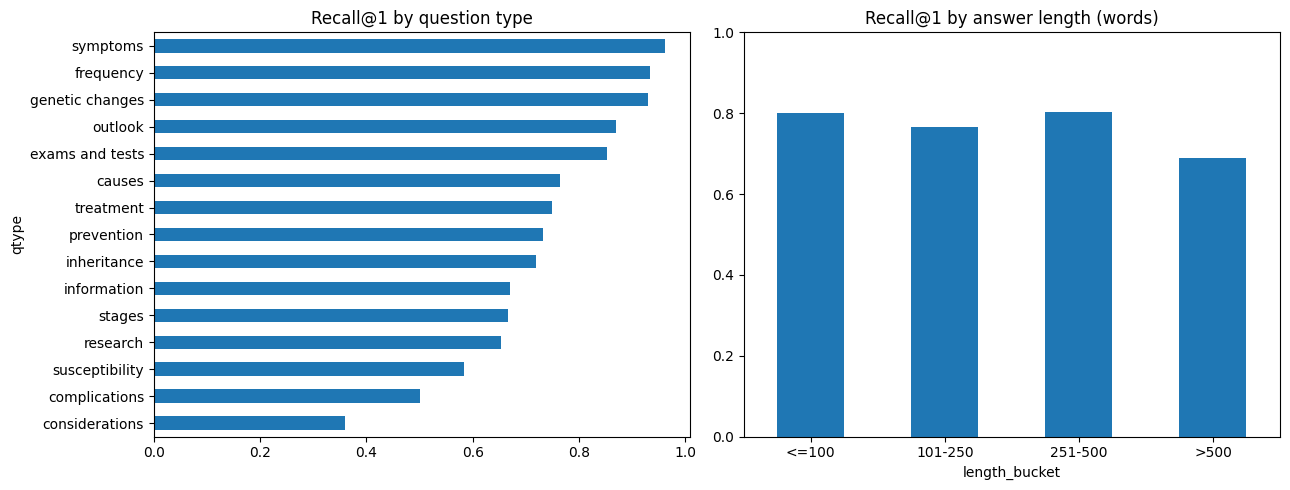

                   n  recall_at_1    mrr
qtype                                   
information      439        0.670  0.779
symptoms         281        0.961  0.978
treatment        239        0.749  0.840
frequency        119        0.933  0.950
genetic changes  100        0.930  0.965
inheritance       89        0.719  0.821
exams and tests   68        0.853  0.911
causes            55        0.764  0.843
susceptibility    48        0.583  0.705
outlook           46        0.870  0.899
prevention        30        0.733  0.822
research          26        0.654  0.755
considerations    25        0.360  0.523
complications      6        0.500  0.616
stages             6        0.667  0.833
                 n  recall_at_1
length_bucket                  
<=100          552        0.801
101-250        616        0.766
251-500        332        0.804
>500            77        0.688


In [ ]:
test = test.copy()
test["position"] = positions(scores_full, gold_full)
test["top1"] = scores_full.argmax(axis=1)
test["top1_similarity"] = scores_full.max(axis=1).round(3)
test["correct_at_1"] = test["position"] == 1
test["answer_words"] = test["answer"].str.split().str.len()

by_type = test.groupby("qtype").agg(
    n=("question", "size"),
    recall_at_1=("correct_at_1", "mean"),
    mrr=("position", lambda p: (1 / p).mean()),
).round(3).sort_values("n", ascending=False)
by_type.to_csv(ROOT / "results/metrics/by_question_type.csv")

test["length_bucket"] = pd.cut(test["answer_words"], [0, 100, 250, 500, 100000],
                               labels=["<=100", "101-250", "251-500", ">500"])
by_length = test.groupby("length_bucket", observed=True).agg(
    n=("question", "size"), recall_at_1=("correct_at_1", "mean")).round(3)
by_length.to_csv(ROOT / "results/metrics/by_answer_length.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
by_type["recall_at_1"].sort_values().plot(kind="barh", ax=axes[0], title="Recall@1 by question type")
by_length["recall_at_1"].plot(kind="bar", ax=axes[1], title="Recall@1 by answer length (words)", rot=0)
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(ROOT / "results/plots/breakdowns.png", dpi=150, bbox_inches="tight")
plt.show()

print(by_type)
print(by_length)

### 6.1 Truncation at the final settings
counts how many KB answers are longer than the final model's maximum input length. Notebook 01 measured truncation at 512 tokens, but the final model reads only `max_len` tokens (256).

In [ ]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(final["model_id"])
sample = kb["answer"].sample(min(2000, len(kb)), random_state=42).tolist()
lengths = np.array([len(ids) for ids in tok(sample)["input_ids"]])

trunc = pd.DataFrame([
    {"limit_tokens": final["max_len"], "pct_answers_longer": round(100 * (lengths > final["max_len"]).mean(), 1)},
    {"limit_tokens": 512, "pct_answers_longer": round(100 * (lengths > 512).mean(), 1)},
])
trunc.to_csv(ROOT / "results/metrics/truncation_final.csv", index=False)
print("Median answer length (tokens):", int(np.median(lengths)))
trunc

Median answer length (tokens): 179


,limit_tokens,pct_answers_longer
0,256,34.4
1,512,8.8


## 7. Error analysis
Every query where the correct answer is **not** ranked first is put into a type, using simple rules (a heuristic, state this in the report). It compares the topic words of the question with the question of the answer that was returned:
- **Same question text:** the same question exists with another valid answer (ambiguous data).
- **Right topic, wrong aspect:** right condition, but another question type (for example treatment instead of symptoms).
- **Right topic, same type, different answer:** right condition, but a different source document.
- **Similar topic name:** a related or similarly named condition.
- **Unrelated topic:** a real retrieval failure.

In [ ]:
STOP = {"what", "are", "is", "the", "of", "for", "to", "how", "who", "at", "risk", "symptoms", "symptom",
        "treatment", "treatments", "causes", "cause", "diagnose", "tests", "exams", "outlook", "prevent",
        "prevention", "genetic", "changes", "related", "inherited", "many", "people", "affected", "does",
        "do", "a", "an", "in", "and", "or", "with", "i", "know", "about", "information", "need", "go",
        "find", "more", "stages", "complications", "considerations", "research", "being", "done", "new",
        "frequency", "susceptibility", "there", "can", "be", "by", "it", "this", "that", "s"}

def topic_tokens(text):
    return set(re.findall(r"[a-z0-9]+", text.lower())) - STOP

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

def error_type(row):
    top = row["top1"]
    retrieved_qs = kb_questions[top]
    if row["question"].lower() in retrieved_qs:
        return "Same question text (ambiguous duplicate)"
    j = max(jaccard(topic_tokens(row["question"]), topic_tokens(q)) for q in retrieved_qs)
    same_type = kb["qtype"].iloc[top] == row["qtype"]
    if j >= 0.8:
        return "Right topic, same type, different answer" if same_type else "Right topic, wrong aspect"
    if j >= 0.3:
        return "Similar topic name"
    return "Unrelated topic"

errors = test[~test["correct_at_1"]].copy()
errors["error_type"] = [error_type(r) for _, r in errors.iterrows()]
errors["retrieved_question"] = [kb["question"].iloc[i] for i in errors["top1"]]
errors["retrieved_qtype"] = [kb["qtype"].iloc[i] for i in errors["top1"]]

print(f"Errors at rank 1: {len(errors)} of {len(test)} ({100 * len(errors) / len(test):.1f}%)")
print(f"Gold answer still in top 5: {100 * (errors['position'] <= 5).mean():.1f}% of the errors")
print(errors["error_type"].value_counts())

errors[["question", "qtype", "position", "error_type", "retrieved_question", "retrieved_qtype", "top1_similarity"]] \
    .to_csv(ROOT / "results/error_analysis/errors.csv", index=False)

for etype in errors["error_type"].unique():
    print("\n" + "=" * 80)
    print(etype)
    for _, row in errors[errors["error_type"] == etype].head(2).iterrows():
        print(f"\nQ: {row['question']}  [{row['qtype']}]  (correct answer ranked {row['position']})")
        print(f"Gold:      {row['answer'][:140]}...")
        print(f"Retrieved: [{row['retrieved_question']}] {kb['answer'].iloc[row['top1']][:140]}...")

Errors at rank 1: 343 of 1577 (21.8%)
Gold answer still in top 5: 73.5% of the errors
error_type
Same question text (ambiguous duplicate)    182
Right topic, wrong aspect                    60
Similar topic name                           51
Unrelated topic                              33
Right topic, same type, different answer     17
Name: count, dtype: int64

Right topic, wrong aspect

Q: Who is at risk for Parasites - Toxoplasmosis (Toxoplasma infection)? ?  [susceptibility]  (correct answer ranked 2)
Gold:      Toxoplasmosis is caused by the protozoan parasite Toxoplasma gondii. In the United States it is estimated that 22.5% of the population 12 ye...
Retrieved: [What is (are) Parasites - Toxoplasmosis (Toxoplasma infection) ?] A single-celled parasite called Toxoplasma gondii causes a disease known as toxoplasmosis. While the parasite is found throughout the world,...

Q: Who is at risk for Hendra Virus Disease (HeV)? ?  [susceptibility]  (correct answer ranked 2)
Gold:      Aust

### 7.1 Successful examples
For the report and the video: show both successes and failures.

In [ ]:
successes = test[test["correct_at_1"]]
for _, row in successes.sample(min(4, len(successes)), random_state=3).iterrows():
    print(f"Q: {row['question']}  [{row['qtype']}]")
    print(f"A: {row['answer'][:200]}...\n")

Q: Is Blau syndrome inherited ?  [inheritance]
A: Blau syndrome is inherited in an autosomal dominant pattern, which means one copy of the altered gene in each cell is sufficient to cause the disorder. Most affected individuals have one parent with t...

Q: What are the symptoms of Hair defect with photosensitivity and mental retardation ?  [symptoms]
A: What are the signs and symptoms of Hair defect with photosensitivity and mental retardation? The Human Phenotype Ontology provides the following list of signs and symptoms for Hair defect with photose...

Q: How many people are affected by leukoencephalopathy with vanishing white matter ?  [frequency]
A: The prevalence of leukoencephalopathy with vanishing white matter is unknown. Although it is a rare disorder, it is believed to be one of the most common inherited diseases that affect the white matte...

Q: What are the genetic changes related to 1p36 deletion syndrome ?  [genetic changes]
A: 1p36 deletion syndrome is caused by a dele

## 8. Out-of-domain questions
The app must refuse questions that are not about health. For each query we take its **highest similarity to any KB answer**. Below a threshold, the app refuses.
- There are **easy** out-of-domain questions (tourism, cooking, sport) and **hard** ones that copy MedQuAD wording about non-medical topics ("What are the symptoms of a failing car battery?"). The hard set shows whether the model only reacts to the question template.
- The threshold is chosen on the **validation** questions plus the **dev** sets (easy + hard), maximizing balanced accuracy (accept in-domain, reject out-of-domain).
- It is then checked on the **test** questions plus the separate **test** sets.
- `THRESH_OVERRIDE` lets you set the threshold by hand after reading the trade-off table.

Chosen threshold: 0.614 (balanced accuracy on val + dev sets: 0.997)
Test in-domain questions accepted: 99.7%
Easy out-of-domain rejected: 100.0%
Hard out-of-domain rejected: 100.0%
Precision of accepted answers: strict 0.783 | question-level 0.899


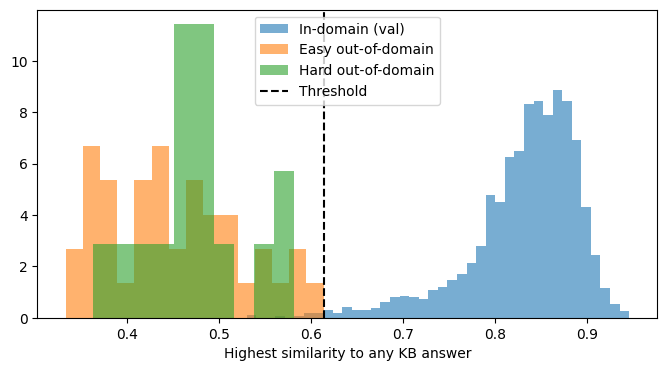

                                               query  max_similarity  \
0     What are the symptoms of a bad car alternator?           0.481   
1          How to prevent mold on my bathroom walls?           0.562   
2            What causes traffic jams in big cities?           0.462   
3          Who is at risk for identity theft online?           0.363   
4        What are the treatments for a leaking roof?           0.479   
5  How many people are affected by the power outage?           0.467   
6  What is the outlook for the tourism industry i...           0.456   
7          How do I treat a wooden deck against rot?           0.448   

   accepted_by_threshold  
0                  False  
1                  False  
2                  False  
3                  False  
4                  False  
5                  False  
6                  False  
7                  False  


,threshold,answered_%,precision_strict,precision_question_level,easy_ood_rejected_%,hard_ood_rejected_%
0,0.647,98.9,0.785,0.901,100.0,100.0
1,0.695,96.4,0.789,0.908,100.0,100.0
2,0.744,90.7,0.801,0.922,100.0,100.0
3,0.793,79.8,0.809,0.939,100.0,100.0
4,0.842,50.0,0.821,0.956,100.0,100.0
5,0.891,9.8,0.812,0.974,100.0,100.0


In [ ]:
ood_dev = [
    "How can I join ALU?", "How do I cook jollof rice?", "Which team won the last World Cup?",
    "How do I write a for loop in Python?", "What is the capital of Kenya?", "Best hotels in Kigali",
    "How do I reset my router password?", "What is the exchange rate for dollars to rwf?",
    "Recommend a good action movie", "How do I invest in stocks?", "How to change a flat tyre?",
    "What is the tallest mountain in Africa?", "How do I apply for a passport?", "Tell me a joke",
    "What is machine learning?", "How do I make a website?", "Best safari parks in Africa",
    "How much is a flight to Paris?", "What is the meaning of life?", "How do I bake a chocolate cake?",
]
ood_test = [
    "Where can I see gorillas?", "How do I fix a leaking tap?", "Who is the president of America?",
    "Explain how a car engine works", "What is the best smartphone to buy?", "How do I learn to play the guitar?",
    "What time zone is Nairobi in?", "How do I convert a PDF to Word?", "Which football team has the most titles?",
    "What is the population of Japan?", "How do I start a small business?", "Give me a recipe for pancakes",
    "What are the best beaches in Zanzibar?", "How do I write a cover letter?", "How does Bitcoin work?",
    "What is the speed of light?", "Plan a three day trip to Cape Town", "How do I train for a marathon?",
    "How do I set up a Wi-Fi network?", "Translate hello into French",
]
ood_dev_hard = [
    "What are the symptoms of a failing car battery?", "How to prevent my laptop from overheating?",
    "What causes inflation in an economy?", "Who is at risk for losing money in crypto trading?",
    "What are the treatments for a cracked phone screen?", "How many people are affected by the new tax law?",
    "What is the outlook for the housing market?", "How do I treat leather to stop it cracking?",
]
ood_test_hard = [
    "What are the symptoms of a bad car alternator?", "How to prevent mold on my bathroom walls?",
    "What causes traffic jams in big cities?", "Who is at risk for identity theft online?",
    "What are the treatments for a leaking roof?", "How many people are affected by the power outage?",
    "What is the outlook for the tourism industry in Rwanda?", "How do I treat a wooden deck against rot?",
]

def max_similarity(questions):
    emb = model.encode([prefix + q for q in questions], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    return (emb @ kb_emb.T).max(axis=1)

val_max = max_similarity(val["question"].tolist())
dev_max = max_similarity(ood_dev)
dev_hard_max = max_similarity(ood_dev_hard)
test_max = scores_full.max(axis=1)
ood_test_max = max_similarity(ood_test)
ood_test_hard_max = max_similarity(ood_test_hard)

def best_threshold(in_scores, ood_scores):
    best_t, best_bal = None, -1.0
    for t in np.unique(np.concatenate([in_scores, ood_scores])):
        bal = ((in_scores >= t).mean() + (ood_scores < t).mean()) / 2
        if bal >= best_bal:
            best_t, best_bal = float(t), bal
    return best_t, best_bal

THRESH, bal = best_threshold(val_max, np.concatenate([dev_max, dev_hard_max]))
THRESH_OVERRIDE = None
if THRESH_OVERRIDE is not None:
    THRESH = THRESH_OVERRIDE
print(f"Chosen threshold: {THRESH:.3f} (balanced accuracy on val + dev sets: {bal:.3f})")

accepted = test_max >= THRESH
print(f"Test in-domain questions accepted: {100 * accepted.mean():.1f}%")
print(f"Easy out-of-domain rejected: {100 * (ood_test_max < THRESH).mean():.1f}%")
print(f"Hard out-of-domain rejected: {100 * (ood_test_hard_max < THRESH).mean():.1f}%")
print(f"Precision of accepted answers: strict {test['correct_at_1'][accepted].mean():.3f} | "
      f"question-level {correct_q[accepted].mean():.3f}")

rows = []
for t in np.round(np.linspace(np.percentile(test_max, 1), np.percentile(test_max, 90), 6), 3):
    keep = test_max >= t
    rows.append({"threshold": t, "answered_%": round(100 * keep.mean(), 1),
                 "precision_strict": round(float(test["correct_at_1"][keep].mean()), 3),
                 "precision_question_level": round(float(correct_q[keep].mean()), 3),
                 "easy_ood_rejected_%": round(100 * float((ood_test_max < t).mean()), 1),
                 "hard_ood_rejected_%": round(100 * float((ood_test_hard_max < t).mean()), 1)})
tradeoff = pd.DataFrame(rows)
tradeoff.to_csv(ROOT / "results/metrics/threshold_tradeoff.csv", index=False)

hard_table = pd.DataFrame({"query": ood_test_hard, "max_similarity": np.round(ood_test_hard_max, 3),
                           "accepted_by_threshold": ood_test_hard_max >= THRESH})
hard_table.to_csv(ROOT / "results/error_analysis/hard_ood_test.csv", index=False)

plt.figure(figsize=(8, 4))
plt.hist(val_max, bins=40, alpha=0.6, label="In-domain (val)", density=True)
plt.hist(np.concatenate([dev_max, ood_test_max]), bins=15, alpha=0.6, label="Easy out-of-domain", density=True)
plt.hist(np.concatenate([dev_hard_max, ood_test_hard_max]), bins=10, alpha=0.6, label="Hard out-of-domain", density=True)
plt.axvline(THRESH, color="k", linestyle="--", label="Threshold")
plt.xlabel("Highest similarity to any KB answer")
plt.legend()
plt.savefig(ROOT / "results/plots/ood_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

print(hard_table)
tradeoff

## 9. Symptom-style queries
Hand-written queries that describe how someone feels, **without naming the disease**. This is harder than the test split, where the question names the condition. A query counts as a hit if the expected condition word appears in the question of one of the top 5 results.

**Edit this list and grow it to about 50.** Items whose keyword is not in the KB (`keyword_in_kb = 0`) are not valid tests, replace them. Read the printed top results yourself: the keyword rule is lenient.

In [ ]:
symptom_tests = [
    ("I am very thirsty, urinate often and feel tired all the time", "diabetes"),
    ("wheezing, shortness of breath and a tight chest", "asthma"),
    ("chest pain spreading to my left arm with sweating", "heart attack"),
    ("severe headache with nausea and sensitivity to light", "migraine"),
    ("high fever, headache and a stiff neck", "meningitis"),
    ("burning pain when urinating and frequent urination", "urinary tract"),
    ("yellow skin and eyes with dark urine", "hepatitis"),
    ("long cough with blood and night sweats", "tuberculosis"),
    ("joint pain and swelling that is worse in the morning", "arthritis"),
    ("blurred vision and eye pain with halos around lights", "glaucoma"),
    ("sudden weakness on one side of the body and slurred speech", "stroke"),
    ("itchy red patches of dry skin", "eczema"),
    ("tiredness, pale skin and shortness of breath", "anemia"),
    ("sore throat, runny nose and cough", "common cold"),
]

sym_emb = model.encode([prefix + q for q, _ in symptom_tests], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
sym_scores = sym_emb @ kb_emb.T
top5 = np.argsort(-sym_scores, axis=1)[:, :5]

rows = []
for i, ((query, keyword), idxs) in enumerate(zip(symptom_tests, top5)):
    titles = [kb["question"].iloc[j] for j in idxs]
    rows.append({
        "query": query, "keyword": keyword,
        "keyword_in_kb": int(kb["question"].str.lower().str.contains(keyword.lower(), regex=False).sum()),
        "hit_at_5": any(keyword.lower() in t.lower() for t in titles),
        "top1_question": titles[0],
        "top1_similarity": round(float(sym_scores[i, idxs[0]]), 3),
        "accepted": bool(sym_scores[i, idxs[0]] >= THRESH),
    })
sym_df = pd.DataFrame(rows)
sym_df.to_csv(ROOT / "results/error_analysis/symptom_queries.csv", index=False)

valid = sym_df[sym_df["keyword_in_kb"] > 0]
print(f"Valid tests: {len(valid)} of {len(sym_df)} (keyword exists in the KB)")
if len(valid):
    print(f"Hit@5 on valid tests: {valid['hit_at_5'].mean():.2f}")
    print(f"Accepted by the threshold: {valid['accepted'].mean():.2f}")
sym_df

Valid tests: 14 of 14 (keyword exists in the KB)
Hit@5 on valid tests: 0.07
Accepted by the threshold: 0.57


,query,keyword,keyword_in_kb,hit_at_5,top1_question,top1_similarity,accepted
0,"I am very thirsty, urinate often and feel tire...",diabetes,209,False,How many people are affected by Urinary Incont...,0.628,True
1,"wheezing, shortness of breath and a tight chest",asthma,16,False,What is (are) Breathing Problems ?,0.701,True
2,chest pain spreading to my left arm with sweating,heart attack,28,False,What is (are) Chest Pain ?,0.622,True
3,severe headache with nausea and sensitivity to...,migraine,27,False,What is the outlook for SUNCT Headache ?,0.562,False
4,"high fever, headache and a stiff neck",meningitis,13,False,What is (are) Neck Injuries and Disorders ?,0.580,False
5,burning pain when urinating and frequent urina...,urinary tract,43,False,How many people are affected by Urinary Incont...,0.687,True
6,yellow skin and eyes with dark urine,hepatitis,64,False,What is (are) Prevent diabetes problems: Keep ...,0.504,False
7,long cough with blood and night sweats,tuberculosis,6,False,What are the symptoms of Cough ?,0.717,True
8,joint pain and swelling that is worse in the m...,arthritis,56,True,What are the treatments for Surviving Cancer ?,0.556,False
9,blurred vision and eye pain with halos around ...,glaucoma,24,False,What is (are) Low Vision ?,0.630,True


### 9.1 Fine-tuned vs zero-shot on symptom-style queries
The fine-tuned model almost never maps a symptom description to the right condition. Here the **zero-shot** version of the same base model gets the same queries, to see whether fine-tuning on disease-name questions made this worse. 

In [ ]:
def symptom_hits(m, kb_vectors):
    emb = m.encode([prefix + q for q, _ in symptom_tests], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    top = top_k_indices(emb @ kb_vectors.T)
    return [any(kw.lower() in kb["question"].iloc[j].lower() for j in row)
            for (_, kw), row in zip(symptom_tests, top)]

hits_tuned = symptom_hits(model, kb_emb)

base = SentenceTransformer(final["model_id"], device=device)
base_emb = base.encode(kb["answer"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=True)
hits_base = symptom_hits(base, base_emb)
del base
torch.cuda.empty_cache()

sym_cmp = pd.DataFrame({
    "query": [q for q, _ in symptom_tests], "keyword": [k for _, k in symptom_tests],
    "fine_tuned_hit@5": hits_tuned, "zero_shot_hit@5": hits_base,
})
sym_cmp.to_csv(ROOT / "results/error_analysis/symptom_comparison.csv", index=False)
print(f"Fine-tuned Hit@5: {np.mean(hits_tuned):.2f} | Zero-shot Hit@5: {np.mean(hits_base):.2f}")
sym_cmp

Batches:   0%|          | 0/246 [00:00<?, ?it/s]

Fine-tuned Hit@5: 0.07 | Zero-shot Hit@5: 0.14


,query,keyword,fine_tuned_hit@5,zero_shot_hit@5
0,"I am very thirsty, urinate often and feel tire...",diabetes,False,False
1,"wheezing, shortness of breath and a tight chest",asthma,False,False
2,chest pain spreading to my left arm with sweating,heart attack,False,False
3,severe headache with nausea and sensitivity to...,migraine,False,False
4,"high fever, headache and a stiff neck",meningitis,False,False
5,burning pain when urinating and frequent urina...,urinary tract,False,False
6,yellow skin and eyes with dark urine,hepatitis,False,False
7,long cough with blood and night sweats,tuberculosis,False,False
8,joint pain and swelling that is worse in the m...,arthritis,True,True
9,blurred vision and eye pain with halos around ...,glaucoma,False,False


## 10. Which common conditions does the KB cover?
Counts KB questions that mention each condition word.
**Why:** MedQuAD is mostly NIH rare-disease pages. If a common condition has 0 questions, the app cannot answer it.

In [ ]:
common = ["malaria", "hiv", "tuberculosis", "typhoid", "pneumonia", "hypertension", "high blood pressure",
          "diabetes", "cholera", "asthma", "anemia", "stroke", "hepatitis", "cancer", "covid", "ebola"]
coverage = pd.DataFrame({
    "condition": common,
    "kb_questions": [int(kb["question"].str.lower().str.contains(c, regex=False).sum()) for c in common],
})
coverage.to_csv(ROOT / "results/metrics/condition_coverage.csv", index=False)
coverage

,condition,kb_questions
0,malaria,3
1,hiv,7
2,tuberculosis,6
3,typhoid,1
4,pneumonia,21
5,hypertension,16
6,high blood pressure,35
7,diabetes,209
8,cholera,1
9,asthma,16


## 11. Export for the web app
Saves the files the app needs and zips them for download.
- `app/kb.csv`: question, answer and type for every KB entry
- `app/kb_embeddings.npy`: answer vectors (float16 to keep the file small, the app converts back)
- `app/config.json`: threshold, query prefix, max length, model ids

The model is located in `models/final`.

In [ ]:
import shutil

app_dir = ROOT / "app"
kb[["question", "answer", "qtype"]].to_csv(app_dir / "kb.csv", index=False)
np.save(app_dir / "kb_embeddings.npy", kb_emb.astype("float16"))

config = {
    "threshold": round(float(THRESH), 4),
    "min_name_overlap": 0.5,
    "prefix": prefix,
    "max_len": int(final["max_len"]),
    "base_model": final["model_id"],
    "run": final["run"],
    "model_hub_repo": "ai-ngabo/healthcare-qa-retriever",
}
with open(app_dir / "config.json", "w") as f:
    json.dump(config, f, indent=2)

shutil.make_archive(str(ROOT / "app_bundle"), "zip", app_dir)
print(config)
print("KB rows:", len(kb), "| embeddings:", kb_emb.shape)
print("Zip:", ROOT / "app_bundle.zip")

{'threshold': 0.6141, 'min_name_overlap': 0.5, 'prefix': '', 'max_len': 256, 'base_model': 'NeuML/pubmedbert-base-embeddings', 'run': 'C_pubmedbert_3ep', 'model_hub_repo': 'ai-ngabo/healthcare-qa-retriever'}
KB rows: 15723 | embeddings: (15723, 768)
Zip: /kaggle/working/healthcare-qa-assistant/app_bundle.zip


## 12. Push the model to the Hugging Face Hub
Uploads the final model so the web app can download it.

In [ ]:
PUSH_TO_HUB = True
HUB_REPO = "alain-ngabo/healthcare-qa-retriever"

if PUSH_TO_HUB:
    from kaggle_secrets import UserSecretsClient
    hf_token = UserSecretsClient().get_secret("HF_TOKEN")
    model.push_to_hub(HUB_REPO, token=hf_token)
    print("Pushed to", HUB_REPO)
else:
    print("Skipped (PUSH_TO_HUB is False)")

Pushed to alain-ngabo/healthcare-qa-retriever
